# SLM1 线性载频：MNIST 全息图、一级衍射与空间滤波

流程为：MNIST 图像 → SLM 复振幅全息图 → 傅里叶面 → 选取 +1 级 → 重建输入场。

研究重点是线性载频如何将目标一级与零级/共轭级分离，以及载频、滤波孔径和滤波器错位对效率与保真度的影响。实验参考 MATLAB 的 `D2NN_Experimental.m`：`gx = gy = 20e3 m^-1`、SLM 像素间距为 `8 um`。

## 使用原则

- 真实 SLM 模型：显示灰度全息图，傅里叶面同时含零级、+1 级与 -1 级，必须经过空间滤波。
- `U_target * exp(1j * carrier_phase)` 只是“已经选出的一级”的理想描述，不能用来研究零级泄漏。
- 无论使用 Arrizon 或 Bolduc 编码，`gx=gy=0` 时都没有空间上可分离的 +1 级，因此无载频图只能作零级重叠基线，**+1 级保真度未定义**。对本 notebook 的零相位 MNIST，Arrizon 编码还会退化成平坦图。
- 选出的 +1 级仍带线性相位（输入倾角）。`demodulated` 场模拟后续光路已重新对准/去倾角；若实验未重新对准，则应保留该倾角。
- 本 notebook 测量的是前端的效率与场保真度，不是 MNIST 分类准确率。

In [9]:
from __future__ import annotations
from dataclasses import dataclass
from pathlib import Path
import struct
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.dpi'] = 120
MNIST_RAW = Path.home() / 'data' / 'MNIST' / 'raw'
FX_PATH = Path('/home/chenlin/Project/Project/Structured_Light_classes/Structured_Light_classes/fx.mat')
OUTPUT_DIR = Path('slm1_carrier_results'); OUTPUT_DIR.mkdir(exist_ok=True)

@dataclass(frozen=True)
class OpticalConfig:
    pixel_pitch: float = 8e-6       # m, SLM1 calibration
    wavelength: float = 633e-9      # m; replace with the experimental laser value
    fourier_lens_f: float = 500e-3  # m; replace with the actual Fourier lens
    slm_shape: tuple[int, int] = (360, 640)  # (y, x), MATLAB input_grid_size
    illuminated_radius: float = 1.20e-3
    gaussian_waist: float = 0.90e-3
    filter_radius: float = 0.80e-3  # m in the Fourier plane; tune from measured spot size

cfg = OpticalConfig(); GX_REF = GY_REF = 20e3
def carrier_report(gx, gy):
    print(f'period x/y = {1/(gx*cfg.pixel_pitch):.2f}, {1/(gy*cfg.pixel_pitch):.2f} pixels')
    #相邻两个像素的载频相位差为
    print(f'phase step x/y = {2*np.pi*gx*cfg.pixel_pitch:.3f}, {2*np.pi*gy*cfg.pixel_pitch:.3f} rad')
    print(f'+1 position = ({cfg.wavelength*cfg.fourier_lens_f*gx*1e3:.2f}, {cfg.wavelength*cfg.fourier_lens_f*gy*1e3:.2f}) mm')
    print(f'radial displacement = {cfg.wavelength*cfg.fourier_lens_f*np.hypot(gx,gy)*1e3:.2f} mm')
carrier_report(GX_REF, GY_REF)

period x/y = 6.25, 6.25 pixels
phase step x/y = 1.005, 1.005 rad
+1 position = (6.33, 6.33) mm
radial displacement = 8.95 mm


`gx = gy = 20e3 m^-1` 对应每轴 6.25 像素一个周期。在这里假设的 633 nm、500 mm 透镜下，+1 级位于 `(6.33, 6.33) mm`，径向偏移 `8.95 mm`。波长和焦距请按真实实验替换；`gx`、`gy` 单位必须是 `m^-1`，坐标 `X`、`Y` 单位必须是 m。

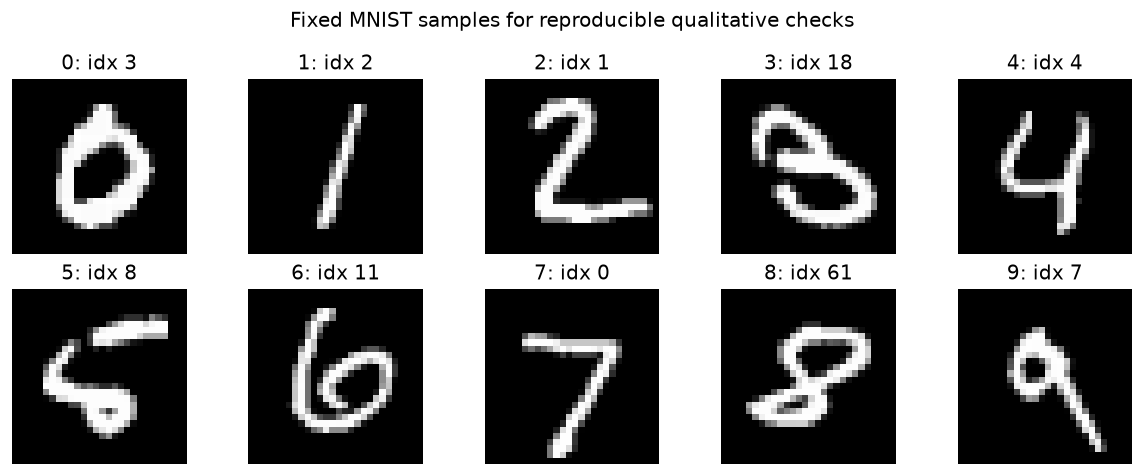

In [10]:
def read_idx_images(path: Path):
    with path.open('rb') as f:
        magic, n, rows, cols = struct.unpack('>IIII', f.read(16))
        if magic != 2051: raise ValueError(f'Bad image IDX magic: {magic}')
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_idx_labels(path: Path):
    with path.open('rb') as f:
        magic, n = struct.unpack('>II', f.read(8))
        if magic != 2049: raise ValueError(f'Bad label IDX magic: {magic}')
        return np.frombuffer(f.read(), dtype=np.uint8)[:n]

images = read_idx_images(MNIST_RAW / 't10k-images-idx3-ubyte')
labels = read_idx_labels(MNIST_RAW / 't10k-labels-idx1-ubyte')
indices = np.array([np.flatnonzero(labels == d)[0] for d in range(10)])
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for d, ax in enumerate(axes.flat):
    ax.imshow(images[indices[d]], vmin=0, vmax=255, cmap='gray'); ax.set_title(f'{d}: idx {indices[d]}'); ax.axis('off')
fig.suptitle('Fixed MNIST samples for reproducible qualitative checks'); fig.tight_layout()

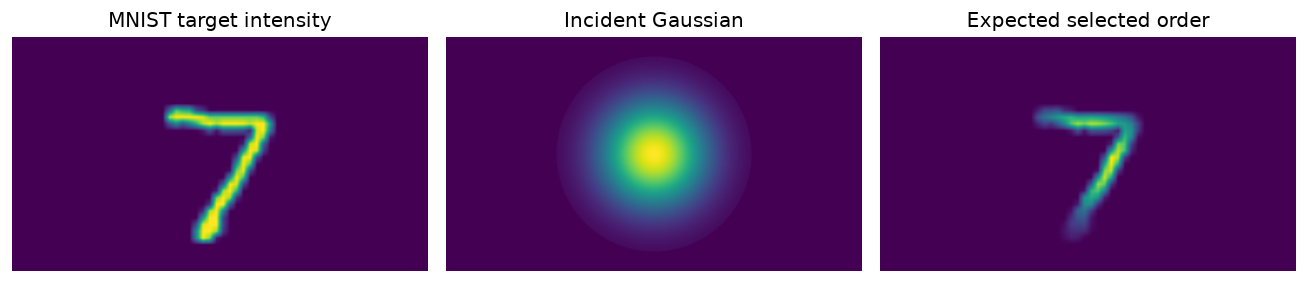

In [11]:
def resize_bilinear(image, shape):
    iy, ix = image.shape; oy, ox = shape
    #在原图坐标中，为输出图每一个像素找对应位置
    ys = np.linspace(0, iy - 1, oy); xs = np.linspace(0, ix - 1, ox)
    y0 = np.floor(ys).astype(int); x0 = np.floor(xs).astype(int)
    y1 = np.minimum(y0 + 1, iy - 1); x1 = np.minimum(x0 + 1, ix - 1)
    wy = (ys - y0)[:, None]; wx = (xs - x0)[None, :]
    top = (1-wx)*image[y0][:, x0] + wx*image[y0][:, x1]
    bottom = (1-wx)*image[y1][:, x0] + wx*image[y1][:, x1]
    return (1-wy)*top + wy*bottom

def coordinates(cfg):
    ny, nx = cfg.slm_shape
    x = (np.arange(nx) - (nx-1)/2) * cfg.pixel_pitch
    y = (np.arange(ny) - (ny-1)/2) * cfg.pixel_pitch
    return x, y, *np.meshgrid(x, y, indexing='xy')

def mnist_field(image_u8, cfg, digit_width_px=280):
    ny, nx = cfg.slm_shape; _, _, X, Y = coordinates(cfg)
    intensity = np.zeros((ny, nx)); small = resize_bilinear(image_u8/255.0, (digit_width_px, digit_width_px))
    y0 = (ny-digit_width_px)//2; x0 = (nx-digit_width_px)//2
    #SLM ROI 中，中心 280×280 是 MNIST 数字
    intensity[y0:y0+digit_width_px, x0:x0+digit_width_px] = small
    #生成圆形有效孔径
    aperture = X**2 + Y**2 <= cfg.illuminated_radius**2
    incident = np.exp(-(X**2 + Y**2)/cfg.gaussian_waist**2) * aperture
    # MNIST values are intensity. Therefore field amplitude is sqrt(I), not I.
    return np.sqrt(intensity)*aperture, incident, aperture

digit = 7
target, incident, aperture = mnist_field(images[indices[digit]], cfg)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for axis, data, title in zip(ax, [np.abs(target)**2, incident**2, np.abs(target*incident)**2], ['MNIST target intensity', 'Incident Gaussian', 'Expected selected order']):
    axis.imshow(data); axis.set_title(title); axis.axis('off')
fig.tight_layout()

## 两种单相位复振幅编码：Arrizon 与 Bolduc

目前 MATLAB 项目使用的是 **Arrizon Type-3**：`Hol = f(A) * sin(Phi + carrier)`，其中 `fx.mat` 是逆 Bessel 振幅查找表。

本 notebook 也实现 **Bolduc** 精确编码：`M = 1 + sinc^{-1}(A)/pi`、`F = Phi - pi*M`、`Psi = M * mod(F + carrier, 2*pi)`。它用振幅相关的闪耀光栅深度，并补偿强度编码带来的附加相位。两种方法都必须在傅里叶面选取 +1 级。Bolduc 模式不依赖 `fx.mat`；Arrizon 精确模式需 `scipy` 读取 `.mat`。

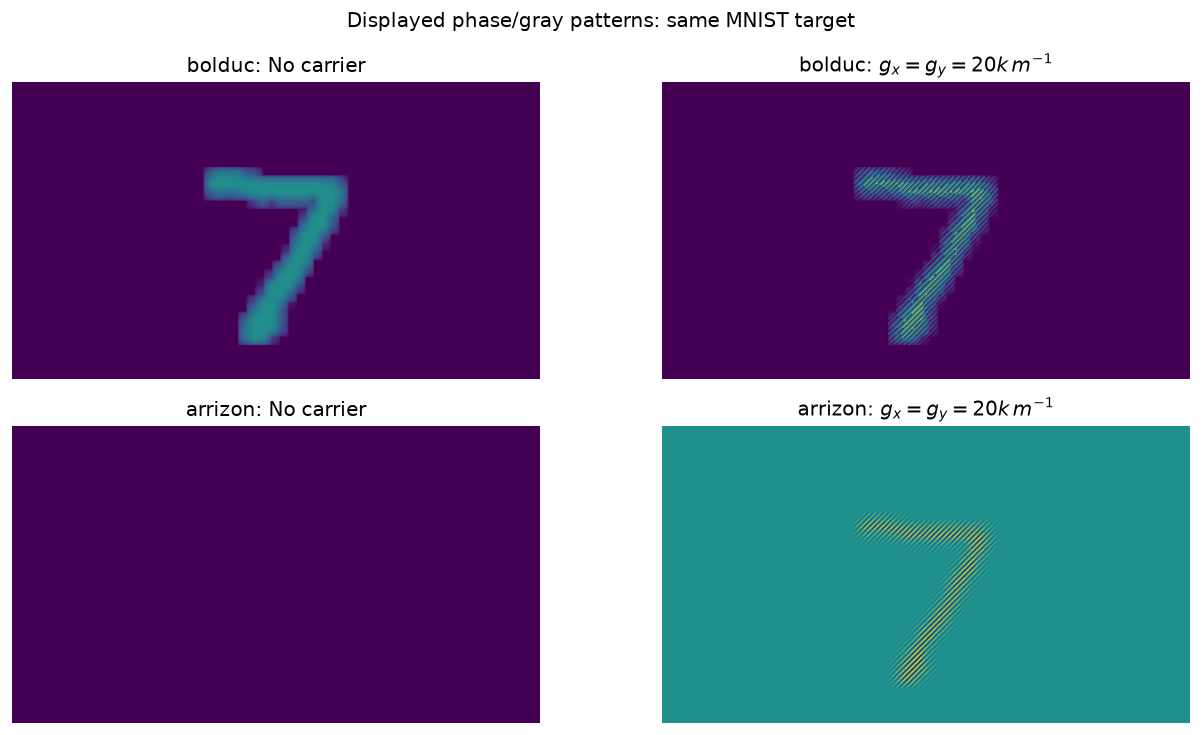

In [18]:
# Compare on the same MNIST field, carrier and Fourier-plane filter.
# 'bolduc' is the default experiment here; 'arrizon' reproduces the existing MATLAB implementation.
# 'phase_only' checks diffraction geometry only and does NOT encode MNIST amplitude.
ENCODER = 'bolduc'

def load_fx(path):
    try: from scipy.io import loadmat
    except ImportError as e: raise ImportError('Install scipy to use MATLAB-equivalent Arrizon encoding.') from e
    fx = np.asarray(loadmat(path)['fx']).squeeze().astype(float)
    if fx.ndim != 1 or len(fx) < 501: raise ValueError(f'Unexpected fx shape {fx.shape}')
    return fx

#计算反sinc(A),利用[-pi, 0]区间的值，使用向量化二分法求解sin(x)/x = A
def inverse_sinc_on_minus_pi_to_zero(amplitude, iterations=48):
    """Solve sin(x)/x = A on [-pi, 0] using vectorized bisection."""
    amplitude = np.clip(amplitude, 0.0, 1.0)
    lower = np.full_like(amplitude, -np.pi, dtype=float); upper = np.zeros_like(amplitude, dtype=float)
    for _ in range(iterations):
        middle = (lower + upper) / 2
        value = np.sinc(middle / np.pi)  # NumPy sinc(z) = sin(pi*z)/(pi*z)
        lower = np.where(value < amplitude, middle, lower)
        upper = np.where(value >= amplitude, middle, upper)
    return (lower + upper) / 2

def hologram(field, gx, gy, *, encoder=ENCODER, fx=None):
    #每个 SLM 像素的真实物理坐标
    _, _, X, Y = coordinates(cfg)
    phi = np.angle(field); carrier = 2*np.pi*(gx*X + gy*Y)
    amplitude = np.abs(field); amplitude = amplitude/amplitude.max() if amplitude.max() else amplitude
    if encoder == 'phase_only': return np.mod(phi + carrier, 2*np.pi)/(2*np.pi)
    if encoder == 'bolduc':
        M = 1 + inverse_sinc_on_minus_pi_to_zero(amplitude)/np.pi
        F = phi - np.pi*M
        psi = M * np.mod(F + carrier, 2*np.pi)
        return psi/(2*np.pi) #除2pi将相位归一化
    if encoder != 'arrizon' or fx is None: raise ValueError('Choose bolduc, arrizon (with fx.mat), or phase_only.')
    # MATLAB fx(round(A/0.002 + 1)); convert the 1-based index to NumPy.
    lut_index = np.clip(np.floor(amplitude/0.002 + 0.5).astype(int), 0, len(fx)-1)
    raw = fx[lut_index] * np.sin(phi + carrier)
    span = raw.max() - raw.min()
    return np.zeros_like(raw) if span <= np.finfo(float).eps else (raw-raw.min())/span

# Use the original MATLAB lookup table for the Arrizon row, irrespective of
# which encoder is selected below for the propagation experiment.
arrizon_fx = load_fx(FX_PATH)
fx = arrizon_fx if ENCODER == 'arrizon' else None

fig, axes = plt.subplots(2, 2, figsize=(11, 6.2))
for row, name in enumerate(('bolduc', 'arrizon')):
    lookup = arrizon_fx if name == 'arrizon' else None
    for col, (gx, gy, label) in enumerate(((0.0, 0.0, 'No carrier'), (GX_REF, GY_REF, r'$g_x=g_y=20k\,m^{-1}$'))):
        data = hologram(target, gx, gy, encoder=name, fx=lookup)
        axes[row, col].imshow(data, vmin=0, vmax=1)
        axes[row, col].set_title(f'{name}: {label}')
        axes[row, col].axis('off')
fig.suptitle('Displayed phase/gray patterns: same MNIST target')
fig.tight_layout()

In [ ]:
def fft2c(u): return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(u)))/np.sqrt(u.size)
def ifft2c(U): return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(U)))*np.sqrt(U.size)

#计算傅里叶焦平面的物理坐标
def focal_coordinates(cfg):
    ny, nx = cfg.slm_shape
    xf = cfg.wavelength*cfg.fourier_lens_f*np.fft.fftshift(np.fft.fftfreq(nx, cfg.pixel_pitch))
    yf = cfg.wavelength*cfg.fourier_lens_f*np.fft.fftshift(np.fft.fftfreq(ny, cfg.pixel_pitch))
    return xf, yf, *np.meshgrid(xf, yf, indexing='xy')

#计算两个复场的归一化重叠度
def overlap(left, right):
    denom = np.linalg.norm(left.ravel())*np.linalg.norm(right.ravel())
    return 0.0 if denom == 0 else float(abs(np.vdot(left, right)/denom)**2)

def run_case(field, incident, aperture, gx, gy, offset_xy=(0., 0.), *, encoder=ENCODER, lookup=None):
    # `lookup` is only needed for Arrizon; Bolduc is analytic and needs no fx.mat.
    if encoder == 'arrizon' and lookup is None: lookup = load_fx(FX_PATH)
    _, _, X, Y = coordinates(cfg); h = hologram(field, gx, gy, encoder=encoder, fx=lookup)
    # Replace this linear response once a measured grayscale-to-phase calibration is available.
    reflected = incident*aperture*np.exp(1j*2*np.pi*h)
    spectrum = fft2c(reflected); xf, yf, XF, YF = focal_coordinates(cfg)
    #目标级次在焦平面的位置
    cx = cfg.wavelength*cfg.fourier_lens_f*gx + offset_xy[0]
    cy = cfg.wavelength*cfg.fourier_lens_f*gy + offset_xy[1]
    mask = (XF-cx)**2 + (YF-cy)**2 <= cfg.filter_radius**2
    #对滤过的频谱做 ifft2c，得到重建场 
    reconstruction = ifft2c(spectrum*mask)
    #人为去掉倾角后，用于与目标场公平比较的光场
    demodulated = reconstruction*np.exp(-1j*2*np.pi*(gx*X + gy*Y))
    reference = incident*field*aperture
    separable_first_order = bool(gx != 0 or gy != 0)
    return dict(hologram=h, spectrum=spectrum, mask=mask, reconstruction=reconstruction, demodulated=demodulated,
                fidelity=overlap(reference, demodulated) if separable_first_order else np.nan,
                filtered_power=float(np.sum(abs(spectrum*mask)**2)/np.sum(abs(spectrum)**2)),
                separable_first_order=separable_first_order)

no_carrier = run_case(target, incident, aperture, 0, 0)
with_carrier = run_case(target, incident, aperture, GX_REF, GY_REF)
print(f"no carrier: filtered P={no_carrier['filtered_power']:.3f}; zero-order-overlap baseline, +1 fidelity undefined")
print(f"with carrier: filtered P={with_carrier['filtered_power']:.3f}, +1 field fidelity={with_carrier['fidelity']:.3f}")

no carrier: filtered P=0.872; zero-order-overlap baseline, +1 fidelity undefined
with carrier: filtered P=0.177, +1 field fidelity=0.938


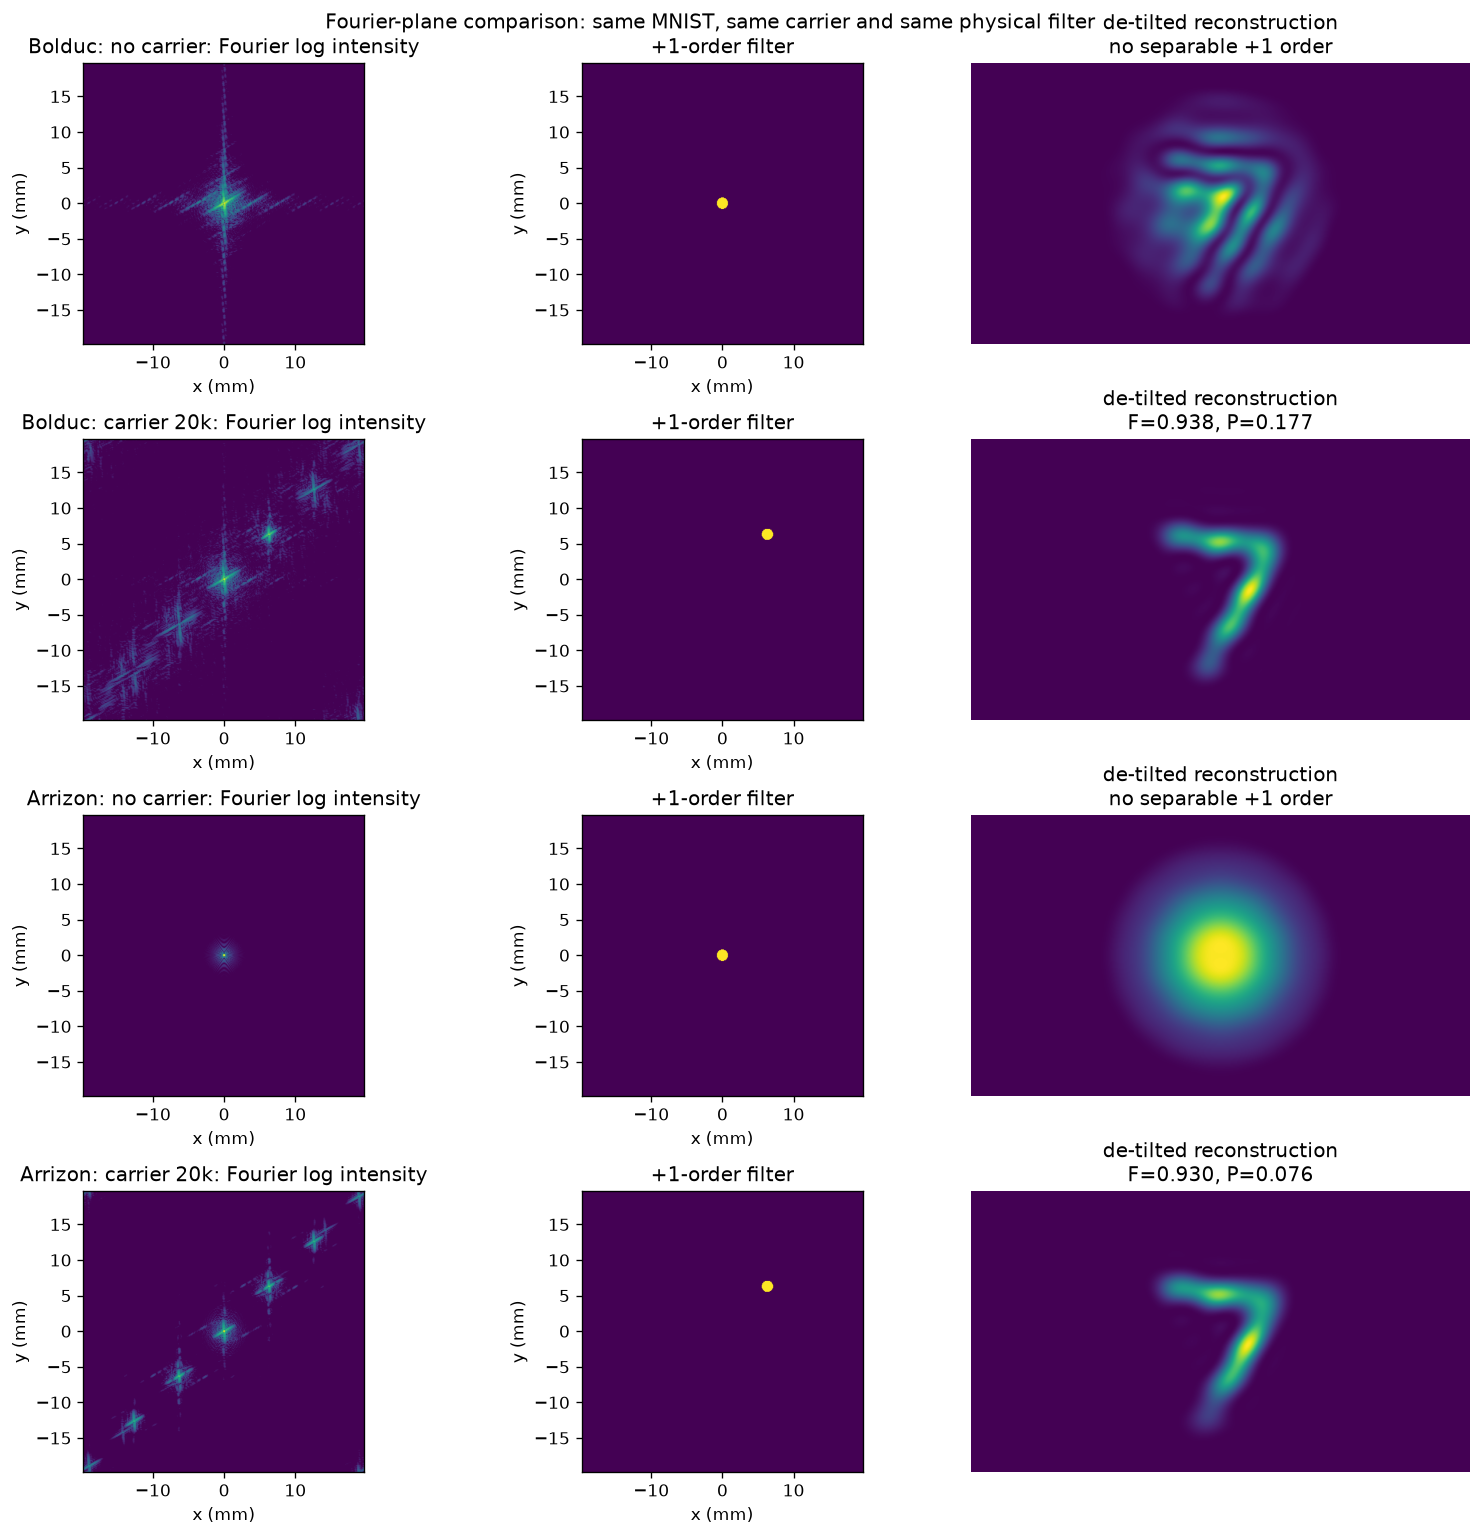

In [20]:
def log_intensity(u):
    I = abs(u)**2; return np.log10(I/I.max() + 1e-7)
xf, yf, _, _ = focal_coordinates(cfg); extent = [xf[0]*1e3, xf[-1]*1e3, yf[0]*1e3, yf[-1]*1e3]
# Explicitly evaluate both encoders here; this plot is independent of ENCODER.
fourier_cases = [
    ('Bolduc: no carrier', run_case(target, incident, aperture, 0.0, 0.0, encoder='bolduc')),
    ('Bolduc: carrier 20k', run_case(target, incident, aperture, GX_REF, GY_REF, encoder='bolduc')),
    ('Arrizon: no carrier', run_case(target, incident, aperture, 0.0, 0.0, encoder='arrizon')),
    ('Arrizon: carrier 20k', run_case(target, incident, aperture, GX_REF, GY_REF, encoder='arrizon')),
]
fig, ax = plt.subplots(4, 3, figsize=(13, 13))
for row, (name, result) in enumerate(fourier_cases):
    ax[row,0].imshow(log_intensity(result['spectrum']), extent=extent, origin='lower', vmin=-6, vmax=0)
    ax[row,0].set(title=f'{name}: Fourier log intensity', xlabel='x (mm)', ylabel='y (mm)')
    ax[row,1].imshow(result['mask'], extent=extent, origin='lower'); ax[row,1].set(title='+1-order filter', xlabel='x (mm)', ylabel='y (mm)')
    ax[row,2].imshow(abs(result['demodulated'])**2)
    metric = 'no separable +1 order' if not result['separable_first_order'] else f"F={result['fidelity']:.3f}, P={result['filtered_power']:.3f}"
    ax[row,2].set(title=f'de-tilted reconstruction\n{metric}')
    ax[row,2].axis('off')
fig.suptitle('Fourier-plane comparison: same MNIST, same carrier and same physical filter')
fig.tight_layout()
# For g=0 the circular filter is centred on the zero order; it cannot isolate +1.

### 只看频谱：零级、理论 +1 级与滤波孔

下图是同一批结果的傅里叶面强度频谱。红色 `+` 是零级 `(0,0)`；青色 `+` 是由光栅方程预测的 +1 级中心；青色圆是实际用于筛选 +1 级的 `filter_radius`。四幅图使用相同的对数色标，因而亮度可以直接比较。

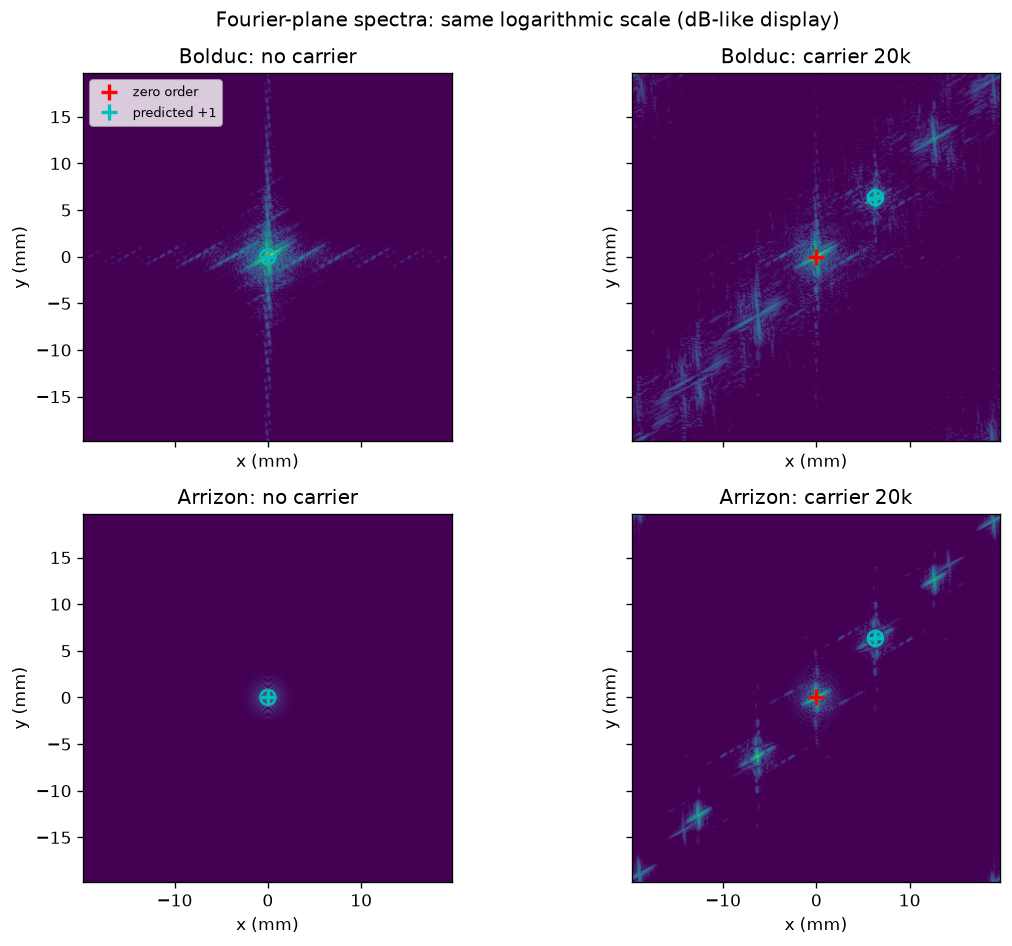

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for axis, (name, result) in zip(axes.flat, fourier_cases):
    axis.imshow(log_intensity(result['spectrum']), extent=extent, origin='lower', vmin=-6, vmax=0)
    has_carrier = result['separable_first_order']
    cx = cfg.wavelength * cfg.fourier_lens_f * GX_REF * 1e3 if has_carrier else 0.0
    cy = cfg.wavelength * cfg.fourier_lens_f * GY_REF * 1e3 if has_carrier else 0.0
    axis.plot(0, 0, 'r+', ms=10, mew=2, label='zero order')
    axis.plot(cx, cy, 'c+', ms=10, mew=2, label='predicted +1')
    axis.add_patch(plt.Circle((cx, cy), cfg.filter_radius*1e3, fill=False, ec='c', lw=1.5))
    axis.set_title(name); axis.set(xlabel='x (mm)', ylabel='y (mm)')
axes[0, 0].legend(loc='upper left', fontsize=8)
fig.suptitle('Fourier-plane spectra: same logarithmic scale (dB-like display)')
fig.tight_layout()

### 同一频谱的角谱表示

这不是新的传播计算：它与上面的傅里叶面频谱是同一份 `spectrum`，只把坐标从焦面位置 `(x_f, y_f)` 改为传播角 `(theta_x, theta_y)`。红色 `+` 是零级；青色 `+` 为理论 +1 级；青色圆是 `filter_radius` 换算到角度后的滤波范围。

+1 carrier angle: (12.66, 12.66) mrad; filter radius: 1.60 mrad


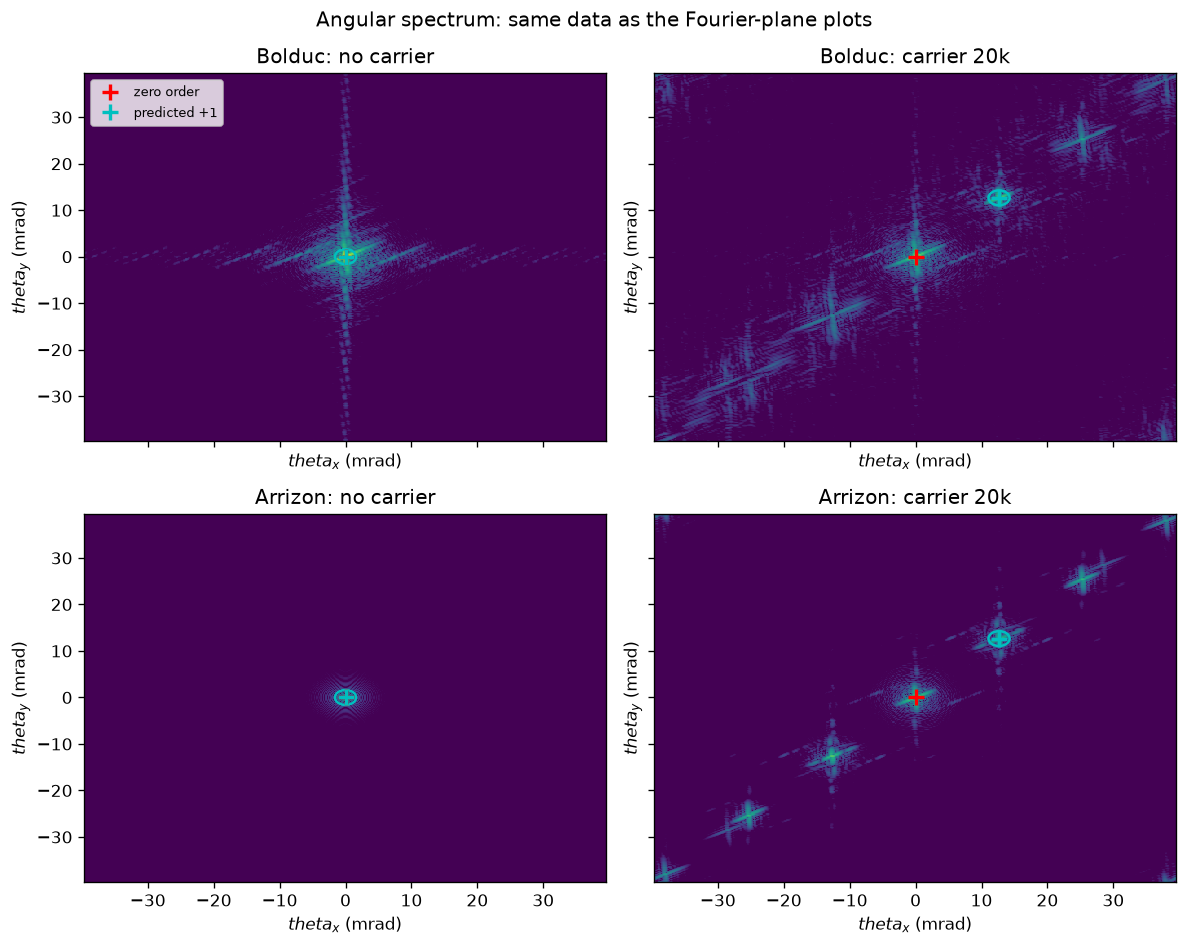

In [23]:
ny, nx = cfg.slm_shape
fx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=cfg.pixel_pitch))
fy_axis = np.fft.fftshift(np.fft.fftfreq(ny, d=cfg.pixel_pitch))
# Exact direction mapping; at these small angles this is almost lambda*f.
theta_x_mrad = np.arcsin(np.clip(cfg.wavelength * fx_axis, -1, 1)) * 1e3
theta_y_mrad = np.arcsin(np.clip(cfg.wavelength * fy_axis, -1, 1)) * 1e3
theta_plus_x = np.arcsin(cfg.wavelength * GX_REF) * 1e3
theta_plus_y = np.arcsin(cfg.wavelength * GY_REF) * 1e3
filter_angle_mrad = np.arctan(cfg.filter_radius / cfg.fourier_lens_f) * 1e3

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for axis, (name, result) in zip(axes.flat, fourier_cases):
    axis.pcolormesh(theta_x_mrad, theta_y_mrad, log_intensity(result['spectrum']), shading='auto', vmin=-6, vmax=0)
    has_carrier = result['separable_first_order']
    cx = theta_plus_x if has_carrier else 0.0
    cy = theta_plus_y if has_carrier else 0.0
    axis.plot(0, 0, 'r+', ms=10, mew=2, label='zero order')
    axis.plot(cx, cy, 'c+', ms=10, mew=2, label='predicted +1')
    axis.add_patch(plt.Circle((cx, cy), filter_angle_mrad, fill=False, ec='c', lw=1.5))
    axis.set(title=name, xlabel=r'$theta_x$ (mrad)', ylabel=r'$theta_y$ (mrad)')
axes[0, 0].legend(loc='upper left', fontsize=8)
fig.suptitle('Angular spectrum: same data as the Fourier-plane plots')
fig.tight_layout()
print(f'+1 carrier angle: ({theta_plus_x:.2f}, {theta_plus_y:.2f}) mrad; filter radius: {filter_angle_mrad:.2f} mrad')

## Arrizon 与 Bolduc：公平的一级光对照

两种方法使用同一张 MNIST、同一入射高斯光、同一个 `gx=gy=20e3 m^-1`、同一个傅里叶面物理圆孔。比较对象不是 SLM 灰度图，而是筛选出的 +1 级。

- `filtered_power`：固定实际圆孔下通过的光功率比例；
- `field_fidelity`：去掉一级残余倾角后，与期望复场的重叠平方；
- 两者的最佳圆孔半径可能不同。因此先进行这个“固定光路”比较；随后可分别扫描 `filter_radius`，比较各自的最佳可达值。

当前 MNIST 是零相位图样，因此主要考察振幅恢复。若要公平验证相位恢复，后续应令 `target` 带已知相位，例如涡旋相位 `exp(1j*l*arctan2(Y,X))`。

bolduc  : filtered power=0.1771, field fidelity=0.9385
arrizon : filtered power=0.0757, field fidelity=0.9298


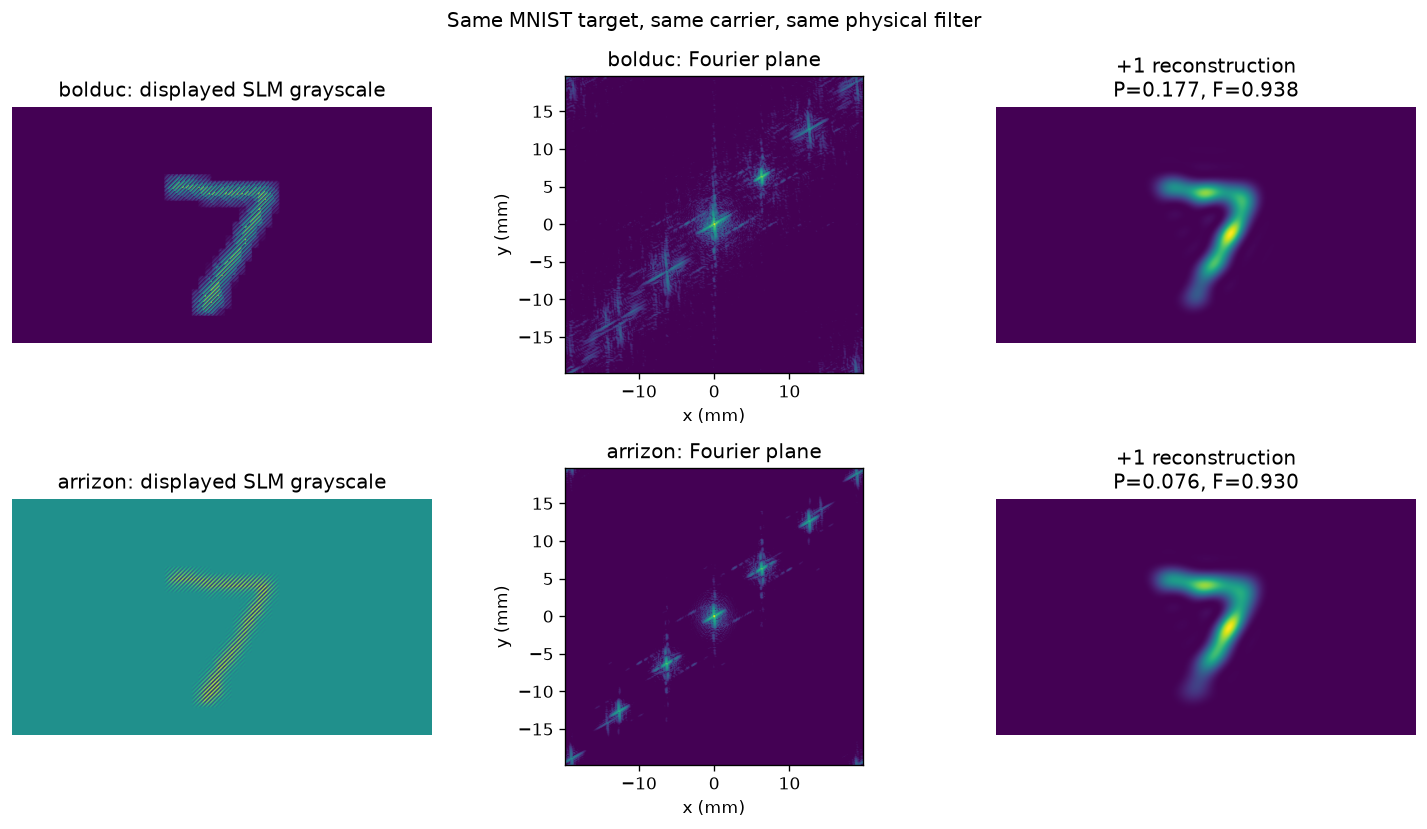

In [ ]:
encoder_results = {}
for name in ('bolduc', 'arrizon'):
    # Arrizon automatically loads the original MATLAB fx.mat lookup table.
    encoder_results[name] = run_case(target, incident, aperture, GX_REF, GY_REF, encoder=name)
    result = encoder_results[name]
    print(f"{name:8s}: filtered power={result['filtered_power']:.4f}, field fidelity={result['fidelity']:.4f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, name in enumerate(('bolduc', 'arrizon')):
    result = encoder_results[name]
    axes[row, 0].imshow(result['hologram'], vmin=0, vmax=1)
    axes[row, 0].set_title(f'{name}: displayed SLM grayscale')
    axes[row, 1].imshow(log_intensity(result['spectrum']), extent=extent, origin='lower', vmin=-6, vmax=0)
    axes[row, 1].set_title(f'{name}: Fourier plane')
    axes[row, 1].set(xlabel='x (mm)', ylabel='y (mm)')
    axes[row, 2].imshow(np.abs(result['demodulated'])**2)
    axes[row, 2].set_title(f"+1 reconstruction\nP={result['filtered_power']:.3f}, F={result['fidelity']:.3f}")
    for col in (0, 2): axes[row, col].axis('off')
fig.suptitle('Same MNIST target, same carrier, same physical filter')
fig.tight_layout()

## 扫描载频与滤波器错位

先比较载频，不应只做开/关：`6.25 px` 是实验值，`8–12 px` 是较保守的相邻候选，`4–5 px` 用于观察像素采样过粗时的趋势。接着在固定实验载频下扫描物理滤波孔中心误差，得到对准容差。`​filter_radius` 需按实测 +1 级光斑大小重新设置。

改变载频周期，观察 +1 级的功率和保真度&固定载频，故意移动空间滤波孔，观察对准容差

/tmp/ipykernel_3673320/2184571541.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


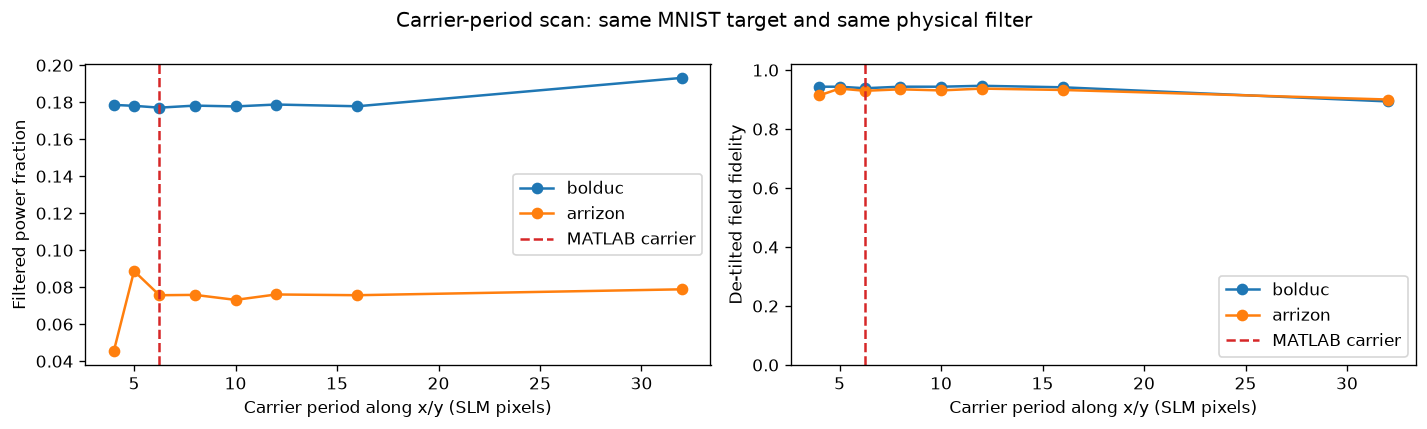

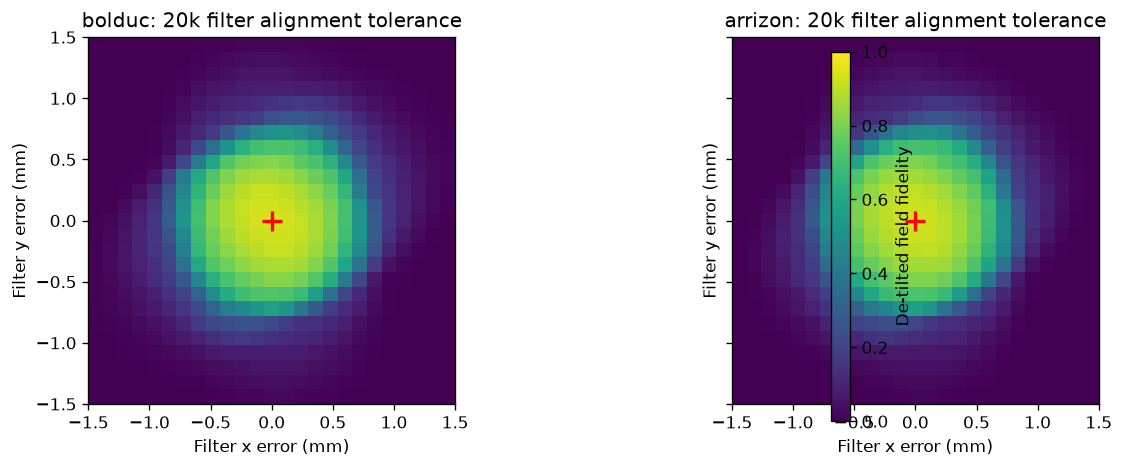

In [22]:
periods = np.array([np.inf, 32, 16, 12, 10, 8, 6.25, 5, 4.])
# period is the number of SLM pixels per 2pi carrier cycle along each axis.
encoder_names = ('bolduc', 'arrizon')
scans = {}
for name in encoder_names:
    lookup = arrizon_fx if name == 'arrizon' else None
    records = []
    for period in periods:
        g = 0.0 if np.isinf(period) else 1 / (period * cfg.pixel_pitch)
        result = run_case(target, incident, aperture, g, g, encoder=name, lookup=lookup)
        records.append((period, result['filtered_power'], result['fidelity']))
    scans[name] = records

finite = np.isfinite(periods)  # exclude the no-carrier baseline: it has no separable +1 order
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for name, color in zip(encoder_names, ('tab:blue', 'tab:orange')):
    records = scans[name]
    powers = [power for period, power, _ in records if np.isfinite(period)]
    fidelities = [fidelity for period, _, fidelity in records if np.isfinite(period)]
    axes[0].plot(periods[finite], powers, 'o-', color=color, label=name)
    axes[1].plot(periods[finite], fidelities, 'o-', color=color, label=name)
for axis, ylabel in zip(axes, ('Filtered power fraction', 'De-tilted field fidelity')):
    axis.axvline(6.25, color='tab:red', ls='--', label='MATLAB carrier')
    axis.set(xlabel='Carrier period along x/y (SLM pixels)', ylabel=ylabel)
    axis.legend()
axes[1].set_ylim(0, 1.02)
fig.suptitle('Carrier-period scan: same MNIST target and same physical filter')
fig.tight_layout()

# Shift the physical Fourier-plane filter while retaining the MATLAB carrier.
offset_mm = np.linspace(-1.5, 1.5, 25)
fidelity_maps = {}
for name in encoder_names:
    lookup = arrizon_fx if name == 'arrizon' else None
    fidelity_map = np.empty((len(offset_mm), len(offset_mm)))
    for iy, dy in enumerate(offset_mm):
        for ix, dx in enumerate(offset_mm):
            fidelity_map[iy, ix] = run_case(
                target, incident, aperture, GX_REF, GY_REF, (dx*1e-3, dy*1e-3),
                encoder=name, lookup=lookup,
            )['fidelity']
    fidelity_maps[name] = fidelity_map

extent_offset = [*offset_mm[[0, -1]], *offset_mm[[0, -1]]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for axis, name in zip(axes, encoder_names):
    image = axis.imshow(fidelity_maps[name], origin='lower', extent=extent_offset, vmin=0, vmax=1)
    axis.plot(0, 0, 'r+', ms=12, mew=2)
    axis.set(title=f'{name}: 20k filter alignment tolerance', xlabel='Filter x error (mm)', ylabel='Filter y error (mm)')
fig.colorbar(image, ax=axes, label='De-tilted field fidelity')
fig.tight_layout()

## 可选：MNIST 测试集统计

在固定载频与光学参数下，对测试集抽样统计前端保真度和选级功率。先用 100 张验证流程；确认滤波半径、SLM 相位响应和光束参数后再扩大。

100-image selected power: 0.2934 ± 0.0935
100-image field fidelity: 0.9602 ± 0.0242


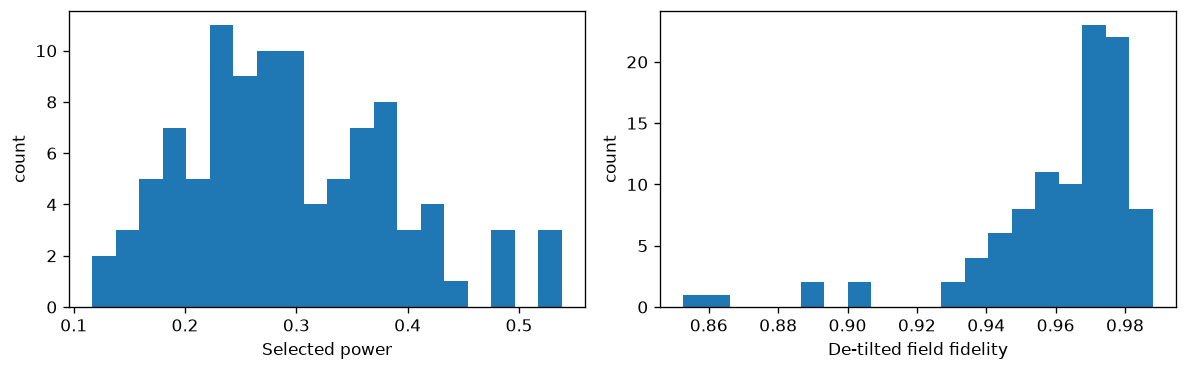

In [17]:
rng = np.random.default_rng(7); sample = rng.choice(len(images), size=100, replace=False)
powers, fidelities = [], []
for i in sample:
    current_target, current_incident, current_aperture = mnist_field(images[i], cfg)
    result = run_case(current_target, current_incident, current_aperture, GX_REF, GY_REF)
    powers.append(result['filtered_power']); fidelities.append(result['fidelity'])
print(f'100-image selected power: {np.mean(powers):.4f} ± {np.std(powers):.4f}')
print(f'100-image field fidelity: {np.mean(fidelities):.4f} ± {np.std(fidelities):.4f}')
fig, ax = plt.subplots(1,2,figsize=(10,3.2))
ax[0].hist(powers, bins=20); ax[0].set(xlabel='Selected power', ylabel='count')
ax[1].hist(fidelities, bins=20); ax[1].set(xlabel='De-tilted field fidelity', ylabel='count')
fig.tight_layout()

## 实验前结论清单

1. 主对照组固定为 MATLAB 实验值 `gx = gy = 20e3 m^-1`；使用 `8–12 px` 周期作保守邻近对照。
2. 真实傅里叶面先确定 +1 级中心和尺寸，再设定滤波孔中心/半径。
3. 取得 SLM 灰度—相位标定后，替换 `exp(1j*2*pi*hologram)` 的线性假设。
4. 若一级没有被后续光路重新对准，必须将其残余倾角保留为后续系统的输入。
5. 若以后做端到端 MNIST 分类，需要单独定义任意图像输入、10 个输出探测区和训练损失；已有 LG 模式分拣结果不可直接复用。